# College Physics 12th Edition

<img src="..//pics/cover.png" width=400> 



In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
# Add root folder to sys.path
sys.path.append(str(Path("..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, oom


In [3]:
!python --version

Python 3.12.10


In [4]:
pwd


'c:\\Users\\crodr\\BK_tech\\Physics\\BK_College_Physics_Serway_12\\ch02'

# Topic 2 - Motion in One Dimension

## Problems
### 2.3 One-Dimensional Motion with Constant Acceleration


#### 26.

page 57

Solve Example 2.6, “Car Chase,” by a graphical method. On
the same graph, plot position versus time for the car and the
trooper. From the intersection of the two curves, read the
time at which the trooper overtakes the car.


In [ ]:
from IPython.display import Math, display
import sympy as sp

# --------------------------------------------------
# Stage 1: Symbolic Derivation (SymPy)
# --------------------------------------------------

# Define symbolic variables with physical assumptions
v_car, a_trooper = sp.symbols("v_car a_trooper", real=True, positive=True)
t_headstart = sp.symbols("t_headstart", real=True, positive=True)
t = sp.symbols("t", real=True, positive=True)  # Time measured from t_B = 0

# Position equations:
# Car position (constant velocity with head start): x_car = v_car * (t + t_headstart)
x_car_expr = sp.simplify(v_car * (t + t_headstart))

# Trooper position (constant acceleration from rest at t_B = 0): x_trooper = (1/2) * a * t^2
x_trooper_expr = sp.simplify(sp.Rational(1, 2) * a_trooper * t**2)

# Equate positions to find overtaking time: x_trooper = x_car
eq_reach = sp.Eq(x_trooper_expr, x_car_expr)

# Solve quadratic equation (1/2)*a*t^2 - v_car*t - v_car*t_headstart = 0
all_solutions = sp.solve(eq_reach, t)

# Mathematically, for a > 0, b < 0, c < 0, the positive physical root is ALWAYS
# the branch with +sqrt(b^2 - 4ac)
t_reach_expr = sp.simplify(all_solutions[1])  # Index 1 corresponds to (+sqrt) branch

# Calculate meeting position
x_reach_expr = sp.simplify(x_trooper_expr.subs(t, t_reach_expr))

# Render symbolic expressions using LaTeX
display(Math(r"\text{Car position: } x_{\text{car}}(t) = " + sp.latex(x_car_expr)))
display(
    Math(
        r"\text{Trooper position: } x_{\text{trooper}}(t) = " + sp.latex(x_trooper_expr)
    )
)
display(
    Math(
        r"\text{Physical overtaking time: } t_{\text{reach}} = "
        + sp.latex(t_reach_expr)
    )
)
display(
    Math(r"\text{Overtaking position: } x_{\text{reach}} = " + sp.latex(x_reach_expr))
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

--- Calculation Results ---
Physical overtaking time : t = 16.94 s (or ~16.9 s)
Physical meeting position : x = 430.66 m (or ~430.7 m)



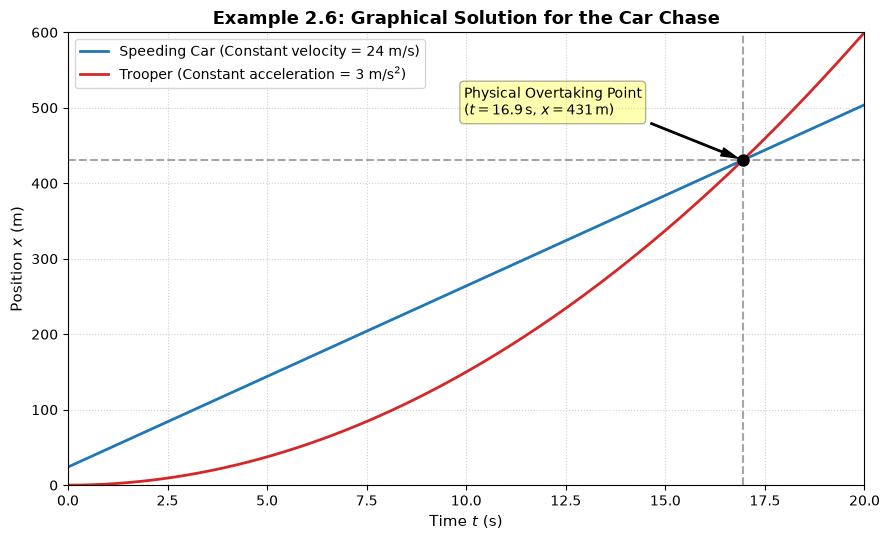

In [ ]:
# --------------------------------------------------
# Stage 2: Numerical Evaluation and Matplotlib Plot
# --------------------------------------------------

# Derive callable numerical functions from SymPy expressions
calc_x_car = sp.lambdify((t, v_car, t_headstart), x_car_expr, modules="numpy")
calc_x_trooper = sp.lambdify((t, a_trooper), x_trooper_expr, modules="numpy")
calc_t_reach = sp.lambdify(
    (v_car, a_trooper, t_headstart), t_reach_expr, modules="numpy"
)
calc_x_reach = sp.lambdify(
    (v_car, a_trooper, t_headstart), x_reach_expr, modules="numpy"
)

# Instantiate quantities with AstroPy units
v_car_qty = 24.0 * (u.m / u.s)
a_trooper_qty = 3.00 * (u.m / (u.s**2))
t_headstart_qty = 1.00 * u.s

# Evaluate physical outputs directly passing Quantity objects
t_reach_qty = calc_t_reach(v_car_qty, a_trooper_qty, t_headstart_qty)
x_reach_qty = calc_x_reach(v_car_qty, a_trooper_qty, t_headstart_qty)

print("--- Calculation Results ---")
print(
    f"Physical overtaking time : t = {t_reach_qty:.2f} (or ~{t_reach_qty.to(u.s):.1f})"
)
print(
    f"Physical meeting position : x = {x_reach_qty:.2f} (or ~{x_reach_qty.to(u.m):.1f})\n"
)

# --------------------------------------------------
# Matplotlib Plot Generation
# --------------------------------------------------
t_vals_qty = np.linspace(0.0, 20.0, 200) * u.s

x_car_vals = calc_x_car(t_vals_qty, v_car_qty, t_headstart_qty)
x_trooper_vals = calc_x_trooper(t_vals_qty, a_trooper_qty)

plt.figure(figsize=(9, 5.5))

# Plot position vs time curves
plt.plot(
    t_vals_qty.to_value(u.s),
    x_car_vals.to_value(u.m),
    label="Speeding Car (Constant velocity = 24 m/s)",
    color="tab:blue",
    linewidth=2,
)
plt.plot(
    t_vals_qty.to_value(u.s),
    x_trooper_vals.to_value(u.m),
    label=r"Trooper (Constant acceleration = 3 $\mathrm{m/s^2}$)",
    color="tab:red",
    linewidth=2,
)

# Mark the physical intersection point
plt.plot(
    t_reach_qty.to_value(u.s), x_reach_qty.to_value(u.m), "ko", markersize=8, zorder=5
)

# Reference dotted lines
plt.axvline(x=t_reach_qty.to_value(u.s), color="gray", linestyle="--", alpha=0.7)
plt.axhline(y=x_reach_qty.to_value(u.m), color="gray", linestyle="--", alpha=0.7)

# Intersection annotation
plt.annotate(
    f"Physical Overtaking Point\n($t = {t_reach_qty.to_value(u.s):.1f}\\,\\mathrm{{s}}$, $x = {x_reach_qty.to_value(u.m):.0f}\\,\\mathrm{{m}}$)",
    xy=(t_reach_qty.to_value(u.s), x_reach_qty.to_value(u.m)),
    xytext=(t_reach_qty.to_value(u.s) - 7, x_reach_qty.to_value(u.m) + 60),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3),
)

# Axes setup and labels
plt.title(
    "Example 2.6: Graphical Solution for the Car Chase", fontsize=13, fontweight="bold"
)
plt.xlabel("Time $t$ (s)", fontsize=11)
plt.ylabel("Position $x$ (m)", fontsize=11)
plt.xlim(0, 20)
plt.ylim(0, 600)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

#### 27. 

An object moving with uniform acceleration has a velocity
of 12.0 cm/s in the positive x - direction when its x-coordinate
is 3.00 cm. If its x - coordinate 2.00 s later is 25.00 cm, what is
its acceleration?

In [17]:
x, x0, v, v0, a = sp.symbols("x, x_0, v, v_0, a", real=True)
t = sp.symbols("t", real=True, positive=True)
# --- Position eq ---
eq_pos = sp.Eq(x, x0 + v0 * t + sp.Rational(1, 2) * a * t**2)
print(f"\n--- Position equation: ---")
display(Math(rf"{sp.latex(eq_pos)}"))

print("\n --- Solve symbolically for a ---")
a_pos_expr = sp.solve(eq_pos, a)[0]
display(Math(rf"a = {sp.latex(a_pos_expr)}"))


--- Position equation: ---


<IPython.core.display.Math object>


 --- Solve symbolically for a ---


<IPython.core.display.Math object>

In [ ]:
# --- Derive callables from SymPy ---
calc_a = sp.lambdify((t, v0, x, x0), a_pos_expr)

# --- Astropy Quantities (_qty suffix) ---
v0_qty = 12.0 * (u.cm / u.s)
x0_qty = 3.00 * u.cm
t_qty = 2.00 * u.s
x_qty = -5.00 * u.cm

# --- calculation ---
a_qty = calc_a(t_qty, v0_qty, x_qty, x0_qty)

print(f"Acceleration:  {a_qty:.3g} ")

Acceleration:  -16 cm / s2 


#### 28. 

In 1865 Jules Verne proposed sending men to the Moon
by firing a space capsule from a 220-m-long cannon with a
final speed of 10.97 km/s. What would have been the unrealistically
large acceleration experienced by the space travelers
during their launch? (A human can stand an acceleration of
15g for a short time.) Compare your answer with the free-fall
acceleration, 9.80 m/s2.

In [26]:
x, x0, v, v0, a = sp.symbols("x, x_0, v, v_0, a", real=True)
t = sp.symbols("t", real=True, positive=True)
# --- Velocity square eq ---
eq_vel_sq = sp.Eq(v**2, v0**2 + 2 * a * x)
print(f"\n--- Velocity square equation: ---")
display(Math(rf"{sp.latex(eq_vel_sq)}"))

print("\n --- Solve symbolically for a ---")
a_vel_sq_expr = sp.solve(eq_vel_sq, a)[0]
display(Math(rf"a = {sp.latex(a_vel_sq_expr)}"))


--- Velocity square equation: ---


<IPython.core.display.Math object>


 --- Solve symbolically for a ---


<IPython.core.display.Math object>

In [ ]:
# --- Derive callables from SymPy ---
calc_a = sp.lambdify((v, v0, x), a_vel_sq_expr)

# --- Astropy Quantities (_qty suffix) ---
v0_qty = 0.0 * (u.m / u.s)
v_qty = 10.97 * (u.km / u.s)
x_qty = 220 * u.m
g_qty = 9.80 * (u.m / u.s**2)

# --- calculation ---
a_qty = (calc_a(v_qty, v0_qty, x_qty)).decompose()

print(f"Acceleration:  {a_qty:.3g} ")

ratio = a_qty / g_qty
print(
    f"Ratio to g:  {ratio:.3g} g (about {round(ratio, -2):,.0f}) times Earth's gravity"
)


Acceleration:  2.74e+05 m / s2 
Ratio to g:  2.79e+04 g (about 27,900) times Earth's gravity


#### 29. 

A truck covers 40.0 m in 8.50 s while uniformly slowing down
to a final velocity of 2.80 m/s. 

* **(a)** Find the truck’s original speed. 

* **(b)** Find its acceleration.

In [5]:
# --------------------------------------------------
# Stage 1: Symbolic Derivation (SymPy)
# --------------------------------------------------

# Define symbolic variables
d, t, v_f = sp.symbols(
    "d t v_f", real=True, positive=True
)  # Known constants (d=40m, t=8.5s, v_f=2.8m/s)
v_0, a = sp.symbols(
    "v_0 a", real=True
)  # System unknowns (original speed, acceleration)

# Set up system of two simultaneous kinematic equations:
# Eq 1: Displacement equation  --> d = v_0 * t + (1/2) * a * t^2
# Eq 2: Velocity equation      --> v_f = v_0 + a * t
eq1 = sp.Eq(d, v_0 * t + sp.Rational(1, 2) * a * t**2)
eq2 = sp.Eq(v_f, v_0 + a * t)

# Solve the system of 2 equations directly for unknowns (v_0, a)
solutions = sp.solve((eq1, eq2), (v_0, a))

v_0_expr = sp.simplify(solutions[v_0])
a_expr = sp.simplify(solutions[a])

# Render symbolic results using LaTeX
display(Math(r"\text{(a) Original speed: } v_0 = " + sp.latex(v_0_expr)))
display(Math(r"\text{(b) Acceleration: } a = " + sp.latex(a_expr)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [45]:
# --------------------------------------------------
# Stage 2: Numerical Evaluation (AstroPy + lambdify)
# --------------------------------------------------

# Derive callable numerical functions
calc_v_0 = sp.lambdify((d, t, v_f), v_0_expr, modules="numpy")
calc_a = sp.lambdify((d, t, v_f), a_expr, modules="numpy")

# Instantiate quantities with AstroPy units
d_qty = 40.0 * u.m
t_qty = 8.50 * u.s
v_f_qty = 2.80 * (u.m / u.s)

# Evaluate results directly passing Quantity objects
v_0_qty = calc_v_0(d_qty, t_qty, v_f_qty)
a_qty = calc_a(d_qty, t_qty, v_f_qty)

# Print Results
print("--- Final Results ---")
print(f"(a) Truck's original speed : {v_0_qty.to(u.m / u.s):.3g}")
print(f"(b) Truck's acceleration   : {a_qty.to(u.m / (u.s**2)):.3g}")

--- Final Results ---
(a) Truck's original speed : 6.61 m / s
(b) Truck's acceleration   : -0.448 m / s2


In [6]:
solutions

{a: (-2*d + 2*t*v_f)/t**2, v_0: (2*d - t*v_f)/t}

#### 30. 

A speedboat increases its speed uniformly from $v_i = 20.0 m/s$ 
to $v_f = 30.0 m/s$ in a distance of $2.00 \times 10^2 m$. 

* **(a)** Draw a coordinate system for this situation and label the relevant
quantities, including vectors. 

* **(b)** For the given information, what single equation is most appropriate for finding the
acceleration? 

* **(c)** Solve the equation selected in part (b) symbolically
for the boat’s acceleration in terms of $v_f, v_i$, and $\Delta x$.

* **(d)** Substitute given values, obtaining that acceleration. 

* **(e)** Find the time it takes the boat to travel the given distance.

In [9]:
delta_x, x0, vf, vi, a = sp.symbols("Delta_x, x_0, v_f, v_i, a", real=True)
t = sp.symbols("t", real=True, positive=True)


print("\n--- Part (b) ---")
# --- Velocity square eq ---
eq_vel_sq = sp.Eq(vf**2, vi**2 + 2 * a * delta_x)
print(f"\n--- Velocity square equation: ---")
display(Math(rf"{sp.latex(eq_vel_sq)}"))

print("\n--- Part (c) ---")
print("\n --- Solve symbolically for a ---")
a_vel_sq_expr = sp.solve(eq_vel_sq, a)[0]
display(Math(rf"a = {sp.latex(a_vel_sq_expr)}"))


--- Part (b) ---

--- Velocity square equation: ---


<IPython.core.display.Math object>


--- Part (c) ---

 --- Solve symbolically for a ---


<IPython.core.display.Math object>

In [ ]:
print("\n--- Part (d) ---")
# Derive callable numerical function
calc_a = sp.lambdify((vf, vi, delta_x), a_vel_sq_expr, modules="numpy")

# --- AstroPy values ---
vi_qty = 20.0 * (u.m / u.s)
vf_qty = 30.0 * (u.m / u.s)
delta_x_qty = 2.00e2 * u.m

a_qty = calc_a(vf_qty, vi_qty, delta_x_qty)
print(f"Boat's acceleration: {a_qty}")



--- Part (d) ---
Acceleration: 1.25 m / s2


In [ ]:
delta_x, x0, vf, vi, a = sp.symbols("Delta_x, x_0, v_f, v_i, a", real=True)
t = sp.symbols("t", real=True, positive=True)

print("\n--- Part (e) ---")

# --- Velocity eq ---
eq_vel = sp.Eq(vf, vi + a * t)
print(f"\n--- Velocity equation: ---")
display(Math(rf"{sp.latex(eq_vel)}"))

print("\n --- Solve symbolically for t ---")
t_vel_expr = sp.solve(eq_vel, t)[0]
display(Math(rf"t = {sp.latex(t_vel_expr)}"))

t_qty = (vf_qty - vi_qty) / a_qty

print(f"Time to travel distance: {t_qty}")



--- Part (e) ---

--- Velocity equation: ---


<IPython.core.display.Math object>


 --- Solve symbolically for t ---


<IPython.core.display.Math object>

Time to travel distance: 8.0 s


#### 31. 

A Cessna aircraft has a liftoff speed of 120. km/h. 

* **(a)** What minimum constant acceleration does the aircraft require if it
is to be airborne after a takeoff run of 240. m? 

* (**b)** How long
does it take the aircraft to become airborne?

In [24]:
x, x0, v, v0, a = sp.symbols("x, x_0, v, v_0, a", real=True)
t = sp.symbols("t", real=True, positive=True)

# --- Velocity square eq ---
eq_vel_sq = sp.Eq(v**2, v0**2 + 2 * a * x)
print(f"\n--- Velocity square equation: ---")
display(Math(rf"{sp.latex(eq_vel_sq)}"))

print("\n --- Solve symbolically for a ---")
a_vel_sq_expr = sp.solve(eq_vel_sq, a)[0]
display(Math(rf"a = {sp.latex(a_vel_sq_expr)}"))



--- Velocity square equation: ---


<IPython.core.display.Math object>


 --- Solve symbolically for a ---


<IPython.core.display.Math object>

In [ ]:
print("\n--- Part (a) ---")


# Derive callable numerical function
calc_a = sp.lambdify((v, v0, x), a_vel_sq_expr, modules="numpy")

# AstroPy units

v_qty = 120 * (u.km / u.h)
v0_qty = 0 * (u.km / u.h)
x_qty = 240 * u.m

a_qty = calc_a(v_qty, v0_qty, x_qty).decompose()

print(f"Required acceleration: {a_qty:.3g}")

print("\n--- Part (b) ---")
# eq: v = v0 + a t ==> t = (v - v0) / a
t_qty = ((v_qty - v0_qty) / a_qty).decompose()

print(f"Required time: {t_qty}")


--- Part (a) ---
Required acceleration: 2.31 m / s2

--- Part (b) ---
Required time: 14.4 s


#### 32. 

An object moves with constant acceleration 4.00 m/s2 and
over a time interval reaches a final velocity of 12.0 m/s. 

* **(a)** If its original velocity is 6.00 m/s, what is its displacement during
the time interval? 

* **(b)** What is the distance it travels during this interval? 

* **(c)** If its original velocity is 26.00 m/s, what is its displacement
during this interval? 

* **(d)** What is the total distance
it travels during the interval in part (c)?

In [ ]:
# --------------------------------------------------
# Stage 1: Symbolic Derivation (SymPy)
# --------------------------------------------------

# Define symbolic variables
v_f, v_i_pos, v_i_neg, a = sp.symbols("v_f v_i_pos v_i_neg a", real=True, positive=True)

# (a) & (c) Displacement expression: delta_x = (v_f^2 - v_i^2) / (2 * a)
delta_x_a_expr = sp.simplify((v_f**2 - v_i_pos**2) / (2 * a))
delta_x_c_expr = sp.simplify((v_f**2 - v_i_neg**2) / (2 * a))

# (d) Total distance when initial velocity is negative: d_total = (v_i^2 + v_f^2) / (2 * a)
distance_d_expr = sp.simplify((v_i_neg**2 + v_f**2) / (2 * a))

# Render symbolic results using LaTeX
display(
    Math(r"\text{(a) and (c) Displacement: } \Delta x = " + sp.latex(delta_x_a_expr))
)
display(
    Math(
        r"\text{(d) Total distance (turning around): } d_{\text{total}} = "
        + sp.latex(distance_d_expr)
    )
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
# --------------------------------------------------
# Stage 2: Numerical Evaluation (AstroPy + lambdify)
# --------------------------------------------------

# Derive callable numerical functions
calc_delta_x = sp.lambdify((v_f, v_i_pos, a), delta_x_a_expr, modules="numpy")
calc_distance = sp.lambdify((v_f, v_i_neg, a), distance_d_expr, modules="numpy")

# Instantiate quantities with AstroPy units
v_f_qty = 12.0 * (u.m / u.s)
v_i_pos_qty = 6.00 * (u.m / u.s)
v_i_neg_qty = 6.00 * (u.m / u.s)  # Magnitude for negative case formula
a_qty = 4.00 * (u.m / (u.s**2))

# Evaluate numerical results directly passing Quantity objects
displacement_a_qty = calc_delta_x(v_f_qty, v_i_pos_qty, a_qty)
displacement_c_qty = calc_delta_x(
    v_f_qty, -6.00 * (u.m / u.s), a_qty
)  # algebraic check
total_distance_d_qty = calc_distance(v_f_qty, v_i_neg_qty, a_qty)

# Print Results
print("--- Final Results ---")
print(f"(a) Displacement (v_i = +6.00 m/s) : {displacement_a_qty:.2f}")
print(f"(b) Distance (v_i = +6.00 m/s)     : {displacement_a_qty:.2f}")
print(f"(c) Displacement (v_i = -6.00 m/s) : {displacement_c_qty:.2f}")
print(f"(d) Total distance (v_i = -6.00 m/s): {total_distance_d_qty:.2f}")

--- Final Results ---
(a) Displacement (v_i = +6.00 m/s) : 13.50 m
(b) Distance (v_i = +6.00 m/s)     : 13.50 m
(c) Displacement (v_i = -6.00 m/s) : 13.50 m
(d) Total distance (v_i = -6.00 m/s): 22.50 m


#### 33. 

In a test run, a certain car accelerates uniformly from
zero to 24.0 m/s in 2.95 s. 

* **(a)** What is the magnitude of the car’s acceleration? 

* **(b)** How long does it take the car to change
its speed from 10.0 m/s to 20.0 m/s? 

* **(c)** Will doubling the
time always double the change in speed? Why?

In [ ]:
v0_qty = 0 * (u.m / u.s)
v_qty = 24.0 * (u.m / u.s)
t_qty = 2.95 * u.s

print("\n--- Part (a) ---")
# eq a = v - v0 / t
a_qty = (v_qty - v0_qty) / t_qty

print(f"Car acceleration magnitude: {a_qty:.3g}")

print("\n--- Part (b) ---")
v2_qty = 20.0 * (u.m / u.s)
v02_qty = 10.0 * (u.m / u.s)

# eq: v = v0 * at ==> t = (v -v0) / a

t2_qty = (v2_qty - v02_qty) / a_qty
print(f"Required time: {t2_qty:.3g}")

print("\n--- Part (c) ---")
print(
    "Yes, For motion with constant acceleration (a), the change in speed is given by Delta_v = a Delta_t."
)
print(
    "Because acceleration a is constant, Delta_v is directly proportional to the time interval Delta_t."
)
print(
    "Therefore, doubling the time interval always doubles the corresponding change in speed."
)



--- Part (a) ---
Car acceleration magnitude: 8.14 m / s2

--- Part (b) ---
Required time: 1.23 s

--- Part (c) ---
Yes, For motion with constant acceleration (a), the change in speed is given by Delta_v = a Delta_t.
Because acceleration a is constant, Delta_v is directly proportional to the time interval Delta_t.
Therefore, doubling the time interval always doubles the corresponding change in speed.


#### 34. 

A jet plane lands with a speed of 100 m/s and can accelerate
at a maximum rate of -5.00 m/s2 as it comes to rest. 

* **(a)** From the instant the plane touches the runway, what is the
minimum time needed before it can come to rest? 

* **(b)** Can this plane land on a small tropical island airport where the
runway is 0.800 km long?

In [ ]:
v0_qty = 100 * (u.m / u.s)
a_qty = -5.00 * (u.m / u.s**2)
v_qty = 0 * (u.m / u.s)  # rest


print("\n--- Part (a) ---")
# eq: v = v0 + a t ==> t = (v - v0) / a
t_qty = (v_qty - v0_qty) / a_qty

print(f"Needed time to stop: {t_qty}")

print("\n--- Part (b) ---")
# eq: x = v0 t + (1/2) a t^2
x_qty = v0_qty * t_qty + (1 / 2) * a_qty * t_qty**2

print(f"No, the minimum required runaway is: {x_qty:,.0f}")



--- Part (a) ---
Needed time to stop: 20.0 s

--- Part (b) ---
No, the minimum required runaway is: 1,000 m


#### 35. 

Speedy Sue, driving at 30.0 m/s, enters a one-lane tunnel.
She then observes a slow-moving van 155 m ahead traveling
at 5.00 m/s. Sue applies her brakes but can accelerate
only at -2.00 m/s2 because the road is wet. Will there be a
collision? State how you decide. If yes, determine how far into
the tunnel and at what time the collision occurs. If no, determine
the distance of closest approach between Sue’s car and
the van.

In [ ]:
# --------------------------------------------------
# Stage 1: Symbolic Derivation (SymPy)
# --------------------------------------------------

# Define symbolic variables
v_s0, v_van, d_0, a_s = sp.symbols("v_s0 v_van d_0 a_s", real=True, positive=True)
t = sp.symbols("t", real=True, positive=True)

# Position equations: x_s(t) = v_s0*t + (1/2)*a_s*t^2 (note: a_s is negative)
# x_v(t) = d_0 + v_van*t
x_s = (
    v_s0 * t - sp.Rational(1, 2) * a_s * t**2
)  # treating a_s as positive magnitude for clarity
x_v = d_0 + v_van * t

# Set up collision equation: x_s(t) = x_v(t)
collision_eq = sp.Eq(x_s, x_v)

# Solve for collision time t
t_solutions = sp.solve(collision_eq, t)
t_collision_expr = t_solutions[0]  # First positive root (earlier collision time)

# Position of collision
pos_collision_expr = sp.simplify(x_v.subs(t, t_collision_expr))

# Render symbolic results using LaTeX
display(Math(r"\text{Collision time: } t = " + sp.latex(t_collision_expr)))
display(Math(r"\text{Collision position: } x = " + sp.latex(pos_collision_expr)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
# --------------------------------------------------
# Stage 2: Numerical Evaluation (AstroPy + lambdify)
# --------------------------------------------------

# Derive callable numerical functions
calc_t_col = sp.lambdify((v_s0, v_van, d_0, a_s), t_collision_expr, modules="numpy")
calc_x_col = sp.lambdify((v_s0, v_van, d_0, a_s), pos_collision_expr, modules="numpy")

# Instantiate quantities with AstroPy units
v_s0_qty = 30.0 * (u.m / u.s)
v_van_qty = 5.00 * (u.m / u.s)
d_0_qty = 155.0 * u.m
a_s_qty = 2.00 * (u.m / (u.s**2))  # Magnitude used in our symbolic formulation

# Evaluate numerical results directly passing Quantity objects
t_col_qty = calc_t_col(v_s0_qty, v_van_qty, d_0_qty, a_s_qty)
x_col_qty = calc_x_col(v_s0_qty, v_van_qty, d_0_qty, a_s_qty)

# Print Results
print("--- Final Results ---")
print(f"Will there be a collision? : Yes (Real positive roots exist)")
print(f"Collision time             : {t_col_qty.to(u.s):.2f}")
print(f"Distance into the tunnel   : {x_col_qty.to(u.m):.1f}")
#

--- Final Results ---
Will there be a collision? : Yes (Real positive roots exist)
Collision time             : 11.38 s
Distance into the tunnel   : 211.9 m
